In [3]:
!pip install tensorflow
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (2 outputs left out)

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist

print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [5]:
print(tf.__version__)

2.22.0-rc0


In [6]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [7]:
# Checking training and testing data

print("Training Images:",X_train.shape)
print("Training Labels:",y_train.shape)

print("Testing Images:",X_test.shape)
print("Testing Labels:",y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [8]:
# Class names of Fashion MNIST dataset

class_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

print("Class Names:")
print(class_names)

Class Names:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


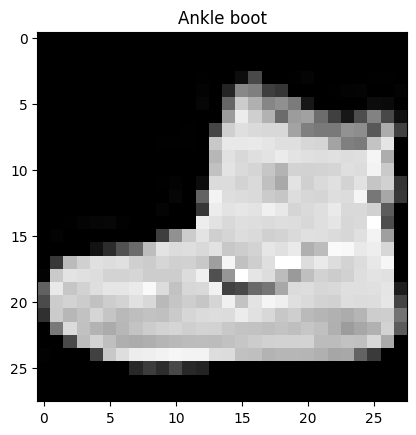

In [9]:
# Display first image

plt.imshow(X_train[0], cmap="gray")

plt.title(class_names[y_train[0]])

plt.show()



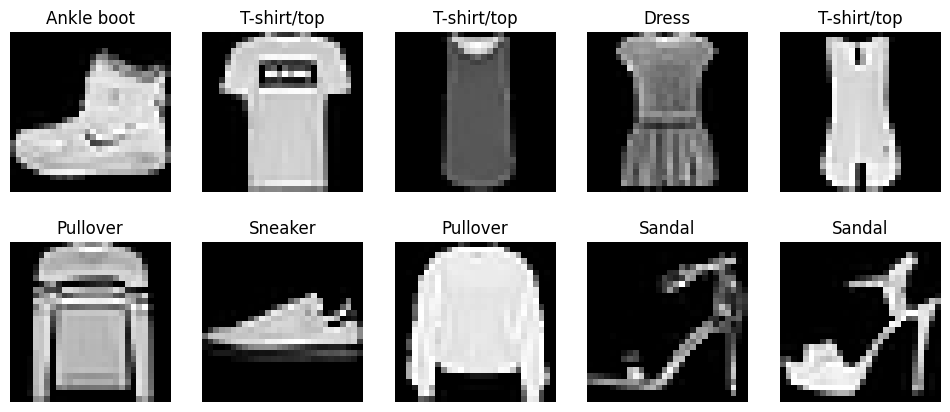

In [13]:
# Display first 10 images

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap="gray")

    plt.title(class_names[y_train[i]])

    plt.axis("off")

plt.show()


In [14]:
# Checking pixel values

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [15]:
# Normalizing image data

X_train = X_train / 255.0

X_test = X_test / 255.0

print("Normalization Completed")

Normalization Completed


In [16]:
# Checking normalized values

print("Minimum Value:", X_train.min())
print("Maximum Value:", X_train.max())

Minimum Value: 0.0
Maximum Value: 1.0


In [17]:
# Checking image shape

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (60000, 28, 28)
Testing Data Shape: (10000, 28, 28)


In [18]:
# Reshaping training images

X_train = X_train.reshape(60000, 28, 28, 1)

# Reshaping testing images

X_test = X_test.reshape(10000, 28, 28, 1)

print("Reshaping Completed")

Reshaping Completed


In [19]:
# Checking new image shape

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

Training Data Shape: (60000, 28, 28, 1)
Testing Data Shape: (10000, 28, 28, 1)


In [20]:
# Importing CNN layers

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

print("CNN Layers Imported Successfully")

CNN Layers Imported Successfully


In [21]:
# Creating CNN model

model = Sequential()

# First Convolution Layer
model.add(Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)))

# First Max Pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second Convolution Layer
model.add(Conv2D(64, (3, 3), activation="relu"))

# Second Max Pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten Layer
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(128, activation="relu"))

# Dropout Layer
model.add(Dropout(0.5))

# Output Layer
model.add(Dense(10, activation="softmax"))

print("CNN Model Created Successfully")

C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN Model Created Successfully


In [22]:
# Displaying model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Compiling CNN model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [24]:
# Training CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

print("Model Training Completed")

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.7771 - loss: 0.6187 - val_accuracy: 0.8485 - val_loss: 0.3984
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8521 - loss: 0.4116 - val_accuracy: 0.8718 - val_loss: 0.3372
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8724 - loss: 0.3607 - val_accuracy: 0.8903 - val_loss: 0.3005
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8827 - loss: 0.3278 - val_accuracy: 0.8947 - val_loss: 0.2864
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8909 - loss: 0.3043 - val_accuracy: 0.8953 - val_loss: 0.2860
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.8975 - loss: 0.2850 - val_accuracy: 0.9030 - val_loss: 0.2636
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9035 - loss: 0.2684 - val_accuracy: 0.9063 - val_loss: 0.2539
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9077 - loss: 0.2513 - 

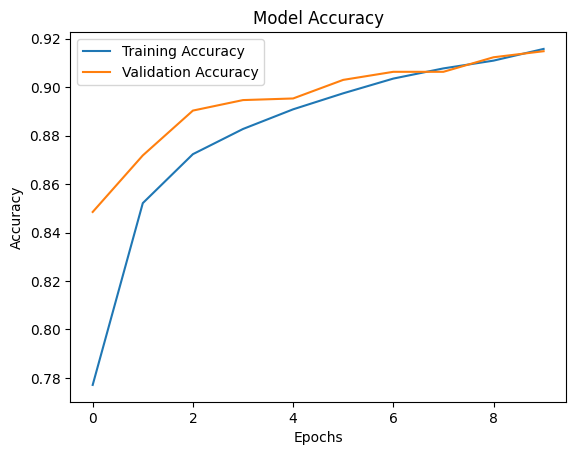

In [25]:
# Training and validation accuracy

plt.plot(history.history["accuracy"])

plt.plot(history.history["val_accuracy"])

plt.title("Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend(["Training Accuracy", "Validation Accuracy"])

plt.show()

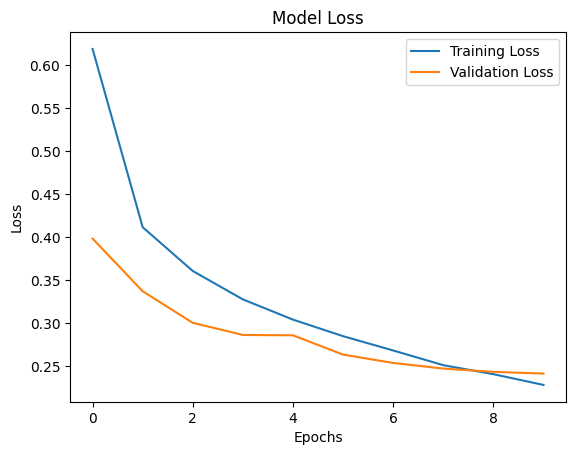

In [26]:
# Training and validation loss

plt.plot(history.history["loss"])

plt.plot(history.history["val_loss"])

plt.title("Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend(["Training Loss", "Validation Loss"])

plt.show()

In [27]:
# Evaluating CNN model

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9085 - loss: 0.2612
Test Loss: 0.2611830532550812
Test Accuracy: 0.9085000157356262


In [28]:
# Converting accuracy into percentage

accuracy = test_accuracy * 100

print("Final Test Accuracy:", accuracy, "%")

Final Test Accuracy: 90.85000157356262 %


In [29]:
# Predicting test images

y_pred = model.predict(X_test)

print("Prediction Completed")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Prediction Completed


In [30]:
# Getting predicted class labels

y_pred = np.argmax(y_pred, axis=1)

print("Predicted Labels:")
print(y_pred[:10])

print("Actual Labels:")
print(y_test[:10])

Predicted Labels:
[9 2 1 1 6 1 4 6 5 7]
Actual Labels:
[9 2 1 1 6 1 4 6 5 7]


In [31]:
# Comparing actual and predicted values

for i in range(10):

    print("Actual:", class_names[y_test[i]])

    print("Predicted:", class_names[y_pred[i]])

    print("-------------------")

Actual: Ankle boot
Predicted: Ankle boot
-------------------
Actual: Pullover
Predicted: Pullover
-------------------
Actual: Trouser
Predicted: Trouser
-------------------
Actual: Trouser
Predicted: Trouser
-------------------
Actual: Shirt
Predicted: Shirt
-------------------
Actual: Trouser
Predicted: Trouser
-------------------
Actual: Coat
Predicted: Coat
-------------------
Actual: Shirt
Predicted: Shirt
-------------------
Actual: Sandal
Predicted: Sandal
-------------------
Actual: Sneaker
Predicted: Sneaker
-------------------


In [32]:
# Importing confusion matrix

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [33]:
# Creating confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[850   1  15  36   3   2  88   0   5   0]
 [  1 973   0  19   2   0   3   0   2   0]
 [ 17   0 876  11  39   0  55   0   2   0]
 [  7   2   8 938  17   0  25   0   3   0]
 [  0   1  56  35 848   0  60   0   0   0]
 [  0   0   0   0   0 983   0  12   0   5]
 [108   1  78  33  66   0 702   0  12   0]
 [  0   0   0   0   0  11   0 971   0  18]
 [  2   0   3   4   1   2   5   2 981   0]
 [  0   0   1   0   0   4   0  32   0 963]]


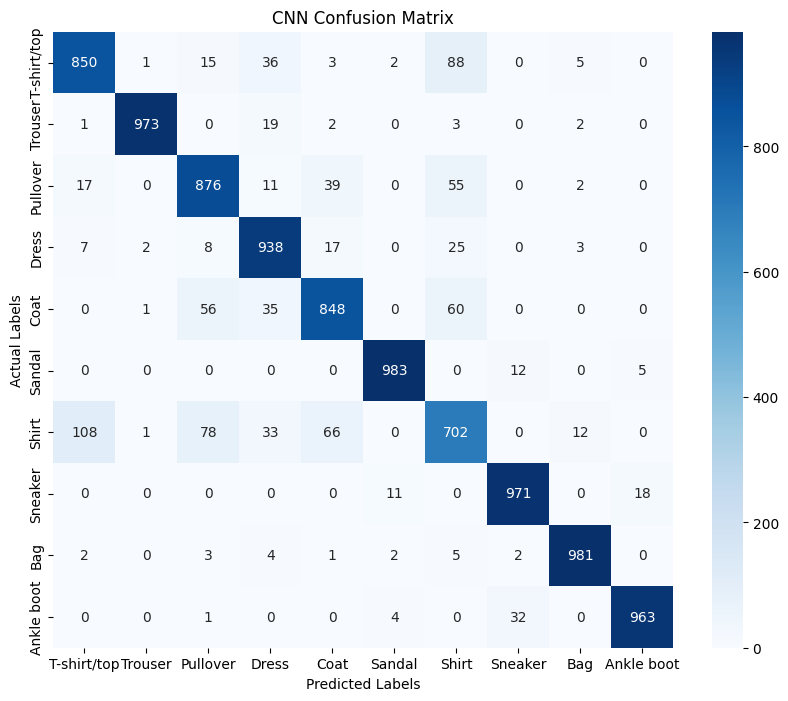

In [34]:
# Displaying confusion matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")

plt.xlabel("Predicted Labels")

plt.ylabel("Actual Labels")

plt.show()

In [35]:
# Displaying classification report

report = classification_report(
    y_test,
    y_pred,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

 T-shirt/top       0.86      0.85      0.86      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.84      0.88      0.86      1000
       Dress       0.87      0.94      0.90      1000
        Coat       0.87      0.85      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.75      0.70      0.72      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



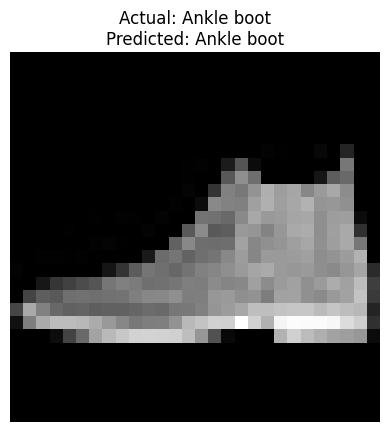

In [36]:
# Displaying actual and predicted image

index = 0

plt.imshow(X_test[index].reshape(28, 28), cmap="gray")

plt.title("Actual: " + class_names[y_test[index]] +
          "\nPredicted: " + class_names[y_pred[index]])

plt.axis("off")

plt.show()

In [37]:
# Checking prediction result

if y_test[index] == y_pred[index]:

    print("Correct Prediction")

else:

    print("Wrong Prediction")

Correct Prediction


In [38]:
# Saving CNN model

model.save("../models/cnn_fashion_mnist.keras")

print("Model Saved Successfully")

Model Saved Successfully


In [39]:
# Loading saved CNN model

from tensorflow.keras.models import load_model

loaded_model = load_model("../models/cnn_fashion_mnist.keras")

print("Model Loaded Successfully")

Model Loaded Successfully


In [40]:
# Checking loaded model

loaded_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

In [41]:
# Predicting using loaded model

test_prediction = loaded_model.predict(X_test[:5])

# Displaying predictions

for i in range(5):

    predicted_class = np.argmax(test_prediction[i])

    actual_class = y_test[i]

    print("Actual:", class_names[actual_class])

    print("Predicted:", class_names[predicted_class])

    print("-------------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Actual: Ankle boot
Predicted: Ankle boot
-------------------
Actual: Pullover
Predicted: Pullover
-------------------
Actual: Trouser
Predicted: Trouser
-------------------
Actual: Trouser
Predicted: Trouser
-------------------
Actual: Shirt
Predicted: Shirt
-------------------


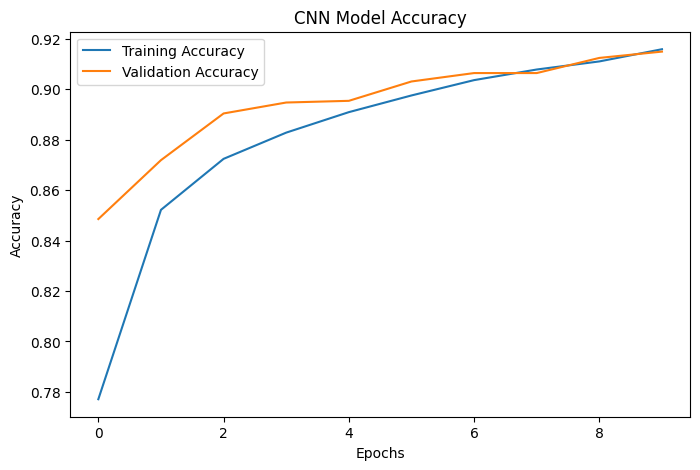

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend(["Training Accuracy", "Validation Accuracy"])

plt.savefig("../reports/accuracy_graph.png")
plt.show()

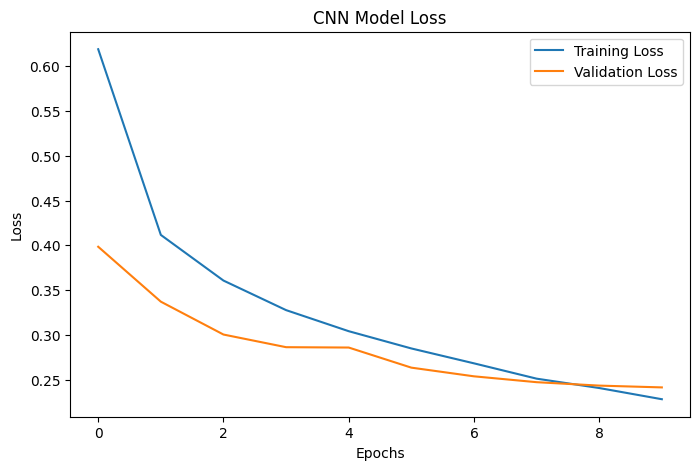

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend(["Training Loss", "Validation Loss"])

plt.savefig("../reports/loss_graph.png")
plt.show()

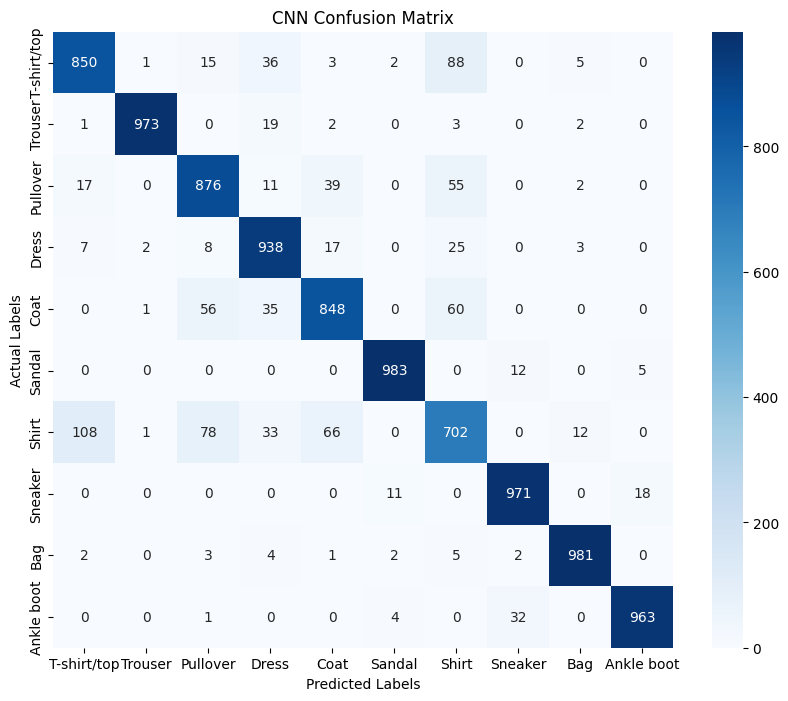

In [44]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.savefig("../reports/confusion_matrix.png")
plt.show()